# 06 · The Agent

So far we have **calculators** (exact math), **rules** (the answer key), and **retrieval** (search over the Selling Guide).
This notebook hands the actual underwriting to an LLM, then measures how well it does:

1. **Tools**: wrap our calculators and the guide search so an LLM can call them
2. **Tool calling**: watch the LLM decide *which* tool it needs
3. **A hand-written loop**: ask → run tools → ask again, until it answers
4. **LangGraph**: the same loop as a graph, plus the system prompt
5. **Sarah (A007)**: the agent underwrites one full applicant file
6. **Evaluation**: run the agent on all 120 generated applicants
7. **Results**: compare the four prompt/model versions

The model is `nvidia/nemotron-3-ultra-550b-a55b`, served free by NVIDIA Build. The key exists in `.env` as `NVIDIA_API_KEY`.

## Setup

In [1]:
import re
import sys
import json
import time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

sys.path.insert(0, str(Path.cwd().parent / "src"))

import pandas as pd
from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_nvidia_ai_endpoints import ChatNVIDIA
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.utils.function_calling import convert_to_openai_tool
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.prebuilt import ToolNode, tools_condition

from mortgage_agent.schemas import Applicant
from mortgage_agent.retrieval import retrieve
from mortgage_agent.tools import ltv, dti, funds_to_close, reserves_months, add_years, search_guide

load_dotenv()

MODEL = "nvidia/nemotron-3-ultra-550b-a55b"
llm = ChatNVIDIA(model=MODEL, temperature=0, max_completion_tokens=4096)

tools = [search_guide, ltv, dti, funds_to_close, reserves_months, add_years]
tools_by_name = {t.name: t for t in tools}
llm_with_tools = llm.bind_tools(tools)

APPLICANTS_DIR = Path("../data/applicants/generated")
RESULTS_ROOT = Path("../results")

## 1. Tools are menu cards

`@tool` turns a plain function into an object with a **name**, a **description** (the docstring), and **arguments**.
The LLM never sees our code. It only sees this card.

In [2]:
print(type(ltv))
print(ltv.name)
print(ltv.description)
print(ltv.args)
print(ltv.invoke({"loan_amount": 320000, "property_value": 400000}))

<class 'langchain_core.tools.structured.StructuredTool'>
ltv
Loan-to-value ratio as a percentage: loan amount divided by property value, times 100.
{'loan_amount': {'title': 'Loan Amount', 'type': 'number'}, 'property_value': {'title': 'Property Value', 'type': 'number'}}
80.0


This is the exact JSON the LLM receives for the `ltv` tool:

In [3]:
print(json.dumps(convert_to_openai_tool(ltv), indent=2))

{
  "type": "function",
  "function": {
    "name": "ltv",
    "description": "Loan-to-value ratio as a percentage: loan amount divided by property value, times 100.",
    "parameters": {
      "properties": {
        "loan_amount": {
          "type": "number"
        },
        "property_value": {
          "type": "number"
        }
      },
      "required": [
        "loan_amount",
        "property_value"
      ],
      "type": "object"
    }
  }
}


Each calculator tool gives the same answers as `calculators.py`:

In [4]:
print(dti.args)
print(dti.invoke({"housing_payment": 2420, "monthly_debts": [450, 120], "monthly_income": 8500}))
print(funds_to_close.invoke({"property_value": 400000, "loan_amount": 320000, "closing_costs": 9000}))
print(reserves_months.invoke({"available_funds": 55000, "cash_to_close": 89000, "monthly_pitia": 2420}))
print(reserves_months.invoke({"available_funds": 95000, "cash_to_close": 89000, "monthly_pitia": 2420}))
print(add_years.invoke({"start_date": "2022-10-30", "years": 4}))
print(add_years.invoke({"start_date": "2024-02-29", "years": 1}))

{'housing_payment': {'title': 'Housing Payment', 'type': 'number'}, 'monthly_debts': {'items': {'type': 'number'}, 'title': 'Monthly Debts', 'type': 'array'}, 'monthly_income': {'title': 'Monthly Income', 'type': 'number'}}
35.18
89000.0
-14.05
2.48
2026-10-30
2025-02-28


### The rulebook tool

`search_guide` wraps our retrieval pipeline. First, check that retrieval finds the right sections:

In [5]:
for q in ["large deposit documentation", "Chapter 7 bankruptcy waiting period", "gift from parents"]:
    print(q, "→", [d.metadata["rule_id"] for d in retrieve(q, top_n=3)])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

large deposit documentation → ['B3-4.2-02', 'B3-4.2-02', 'B3-4.2-02']
Chapter 7 bankruptcy waiting period → ['B3-5.3-07', 'B3-5.3-07', 'B3-5.3-07']
gift from parents → ['B3-4.3-04', 'B3-4.3-04', 'B3-4.3-05']


What the LLM actually gets back from one search. Every character here costs tokens, so shorter is better:

In [6]:
result = search_guide.invoke({"query": "large deposit documentation"})
print(len(result), "characters")
print(result[:700])

3797 characters
Fannie Mae Selling Guide, B3-4.2-02: Depository Accounts

loan.  When bank statements (typically covering the most recent two months) are used, the lender must
evaluate large deposits. See B3-4.1-04, Virtual Currency for additional information when a large deposit may be
from virtual currency that was exchanged into U.S. dollars. Requirements for evaluating large deposits vary
based on the transaction type, as shown in the table below.
Transaction Type
Evaluation Requirements
Refinance transactions
Documentation or explanation for large deposits is not required; however,
the lender remains responsible for ensuring that any borrowed funds,
including any related liability, are considered.
Tran


## 2. Tool calling: the LLM picks a tool

`bind_tools` hands the menu cards to the LLM. Now, instead of answering in text, it can reply with an
**order slip** (`tool_calls`) asking us to run a tool.

In [7]:
response = llm_with_tools.invoke("What is the LTV for a $320,000 loan on a $400,000 home?")
print("Text:", repr(response.content))
print("Tool calls:", response.tool_calls)

Text: ''
Tool calls: [{'name': 'ltv', 'args': {'loan_amount': 320000, 'property_value': 400000}, 'id': 'call-5b296620-4beb-48f0-86cd-dfed68379818', 'type': 'tool_call'}]


The LLM only *asks*. **We** run the tool:

In [8]:
if response.tool_calls:
    call = response.tool_calls[0]
    print(tools_by_name[call["name"]].invoke(call["args"]))

80.0


A question that needs no tool gets a plain text answer:

In [9]:
response = llm_with_tools.invoke("What does LTV stand for?")
print("Text:", response.content)
print("Tool calls:", response.tool_calls)

Text: 
Tool calls: [{'name': 'search_guide', 'args': {'query': 'LTV'}, 'id': 'call-05cd5a2f-ec9d-4fd4-a599-64f1035c2469', 'type': 'tool_call'}]


A rules question should send it to the guide:

In [10]:
response = llm_with_tools.invoke("Does a $40,000 bank deposit need to be documented for a mortgage?")
print("Tool calls:", response.tool_calls)

Tool calls: [{'name': 'search_guide', 'args': {'query': 'large deposit documentation'}, 'id': 'call-3a2abe86-c5c9-42e5-a000-2954edbbc13b', 'type': 'tool_call'}]


## 3. The agent loop, by hand

An agent is just a loop:

1. Send the conversation to the LLM
2. If it asks for tools, run them and add the results to the conversation (as `ToolMessage`s)
3. Repeat until it answers in text

This pattern is called **ReAct**: Reason, then Act, then Reason again.

In [2]:
def run_agent(question: str, max_steps: int = 10) -> str:
    """Ask the LLM, run any tools it needs, and repeat until it answers."""
    messages = [HumanMessage(question)]
    for step in range(max_steps):
        response = llm_with_tools.invoke(messages)
        messages.append(response)

        if not response.tool_calls:
            return response.content

        for call in response.tool_calls:
            print(f"Step {step + 1}: {call['name']}({call['args']})")
            result = tools_by_name[call["name"]].invoke(call["args"])
            messages.append(ToolMessage(content=str(result), tool_call_id=call["id"]))
    return "Stopped: too many steps."

In [3]:
print(run_agent("What is the LTV for a $320,000 loan on a $400,000 home?"))

Step 1: ltv({'loan_amount': 320000, 'property_value': 400000})
The LTV (Loan-to-Value) ratio for a $320,000 loan on a $400,000 home is **80%**.


In [13]:
print(run_agent(
    "A borrower's Chapter 7 bankruptcy was discharged on 2022-10-31. "
    "The new loan closes on 2026-10-30. Is the waiting period met?"
))

Step 1: search_guide({'query': 'Chapter 7 bankruptcy waiting period'})
Step 2: add_years({'start_date': '2022-10-31', 'years': 4})
The waiting period for a Chapter 7 bankruptcy under Fannie Mae guidelines is **4 years** measured from the discharge date (unless extenuating circumstances reduce it to 2 years, which is not indicated here).

- Discharge date: **2022‑10‑31**  
- 4‑year waiting period ends: **2026‑10‑31** (calculated with the `add_years` tool)  
- Proposed closing date: **2026‑10‑30**

Since the closing date (**2026‑10‑30**) falls **one day before** the 4‑year anniversary of the discharge, the required waiting period has **not** been satisfied.

**Answer:** No, the waiting period is not met. The loan would need to close on or after 2026‑10‑31 to satisfy the standard 4‑year waiting period for a Chapter 7 bankruptcy.


## 4. The same loop with LangGraph

LangGraph draws the loop as a graph:

- **State**: the list of messages (`MessagesState` appends new ones)
- **Nodes**: `llm` (think) and `tools` (act)
- **Edges**: after `llm`, `tools_condition` goes to `tools` or ends. After `tools`, always back to `llm`

The **system prompt** is the underwriter's job description. It is added in front of every LLM call.

The prompt below is the **final version (v4)**. It went through four rounds, each one aimed at a problem found in the previous evaluation:

| Version | Change | Why |
|---|---|---|
| v1 | Base prompt | |
| v2 | Mandatory tool calls; "the file lists all assets"; stricter decision definitions; standard waiting periods only | v1 skipped calculations and turned declines into conditions ("go find more money") |
| v3 | "A gift with a letter is fully documented" | v2 asked for proof of gift transfers, which the dataset doesn't model |
| v4 | Reworded: a letter documents a gift but doesn't make it acceptable | v3 started approving gifts that aren't allowed |

In [4]:
SYSTEM_PROMPT = """You are a mortgage underwriter reviewing a purchase loan application against the Fannie Mae Selling Guide, Part B3.

How to work:
- Review the whole file: credit history, debt-to-income, funds to close and reserves, large deposits, and gifts.
- Before applying any rule, look it up with search_guide. Never rely on memory for limits, waiting periods, or documentation requirements.
- Search each topic at most twice. If the guide does not cover something, say so and move on.
- Use the tools for every calculation and every date. Never do arithmetic in your head.
- For every file, call dti and funds_to_close. For every bankruptcy or foreclosure, call add_years to find the date the waiting period ends, then compare it to closing_date.
- Cite the rule ID (for example B3-6-02) for every finding.

Project assumptions:
- All loans are underwritten through DU, are fixed-rate, and have one borrower.
- There are no extenuating circumstances.
- The purchase price equals the property value.
- Measure waiting periods up to the closing_date.
- The Eligibility Matrix is not available, so do not check maximum LTV limits.
- Because there are no extenuating circumstances, always use the standard waiting period. Never use a shorter waiting period, or its additional requirements, that applies only with extenuating circumstances.
- A gift letter fully documents a gift, including the transfer of funds. It does not make the gift acceptable: still check the donor and whether gifts are allowed for this occupancy.

What the file fields mean:
- monthly_housing_payment is the proposed monthly PITIA.
- monthly_income is what the borrower states; verified_monthly_income is what their documents show.
- months_remaining is null for revolving debt such as credit cards.
- bank_balance already includes any large_deposits listed.
- gifts are not included in bank_balance.
- The file lists all of the borrower's assets. There are no other accounts or funds.

Decisions:
- approve: the file meets every requirement as it stands.
- approve with conditions: the file meets every requirement once documentation is provided for something already in it, such as the source of a listed deposit or a letter for a listed gift.
- decline: the file fails a requirement that documentation cannot fix.

A condition can never ask for additional funds, a different gift donor, or changes to the loan. If the borrower is short of money using only what the file shows, that is a decline.
Only add a condition if the file fails without it. If a requirement is already met, do not ask for extra documentation.

Keep your write-up short: one line per check, under 250 words in total.
Then finish with exactly these two lines:
DECISION: <approve | approve with conditions | decline>
RULES: <comma-separated rule IDs that caused a decline or condition, or none>"""

In [5]:
def call_llm(state: MessagesState) -> dict:
    """Node: send the whole conversation to the LLM and return its reply."""
    messages = [SystemMessage(SYSTEM_PROMPT)] + state["messages"]
    return {"messages": [llm_with_tools.invoke(messages)]}


builder = StateGraph(MessagesState)
builder.add_node("llm", call_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "llm")
builder.add_conditional_edges("llm", tools_condition)
builder.add_edge("tools", "llm")

graph = builder.compile()

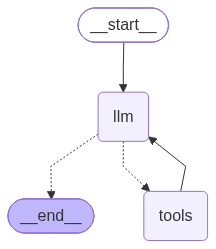

7966

In [16]:
png = graph.get_graph().draw_mermaid_png()
display(Image(png))
Path("../docs").mkdir(exist_ok=True)
Path("../docs/agent_graph.png").write_bytes(png)

The agent ends every answer with two fixed lines (`DECISION:` and `RULES:`). This parser reads them so Python can grade the answer.
`message_text` handles models that return their answer as a list of parts instead of one string.

In [7]:
import re

DECISIONS = {"approve", "approve with conditions", "decline"}
RULE_ID = r"B3-\d+(?:\.\d+)*-\d+"


def parse_decision(text: str) -> dict:
    """Read the DECISION and RULES lines from the agent's final answer."""
    text = text.replace("\u2011", "-").replace("\u2010", "-").replace("\u2013", "-")

    decision_line = re.search(r"DECISION:\s*(.+)", text, re.IGNORECASE)
    rules_line = re.search(r"RULES:\s*(.+)", text, re.IGNORECASE)

    decision = decision_line.group(1).strip().strip("*. ").lower() if decision_line else None
    rule_ids = sorted(set(re.findall(RULE_ID, rules_line.group(1)))) if rules_line else []

    return {"decision": decision if decision in DECISIONS else None, "rule_ids": rule_ids}


def message_text(message) -> str:
    """The text of a message, whether the model returned one string or a list of parts."""
    if isinstance(message.content, str):
        return message.content
    return "".join(part.get("text", "") for part in message.content if isinstance(part, dict))

The bankruptcy question again, now through the graph:

In [ ]:
result = graph.invoke(
    {"messages": [HumanMessage(
        "A borrower's Chapter 7 bankruptcy was discharged on 2022-10-31. "
        "The new loan closes on 2026-10-30. Is the waiting period met?"
    )]},
    config={"recursion_limit": 20},
)

for message in result["messages"]:
    message.pretty_print()

    

================================ Human Message =================================

A borrower's Chapter 7 bankruptcy was discharged on 2022-10-31. The new loan closes on 2026-10-30. Is the waiting period met?
================================== Ai Message ==================================
Tool Calls:
  search_guide (call-ea3a204c-d35b-4dd5-a164-4dc39cbfa8d1)
 Call ID: call-ea3a204c-d35b-4dd5-a164-4dc39cbfa8d1
  Args:
    query: Chapter 7 bankruptcy waiting period
================================= Tool Message =================================
Name: search_guide

Fannie Mae Selling Guide, B3-5.3-07: Significant Derogatory Credit Events — Waiting Periods and Re-establishing Credit

Credit Events in the Credit Report above for additional information.
Summary — All Waiting Period Requirements
The following table summarizes the waiting period requirements for all significant derogatory credit events.
Derogatory Event
Waiting Period
Requirements
Waiting Period with
Extenuating Circumstances
B

## 5. Sarah (A007): a full applicant file

The agent sees the whole file **except** `expected`, which is the answer key.
Sarah's correct answer is **approve with conditions (B3-4.2-02)**: her $40,000 deposit is undocumented, and she needs it to close.

In [8]:
def applicant_file(applicant: Applicant) -> str:
    """The applicant's file as the agent sees it: everything except the answer key."""
    return applicant.model_dump_json(exclude={"expected"})


sarah = Applicant.model_validate_json(Path("../data/applicants/A007.json").read_text())
file_text = applicant_file(sarah)

print(file_text)
print("Answer key hidden:", "expected" not in file_text)

{"applicant_id":"A007","name":"Sarah Chen","closing_date":"2026-10-30","loan":{"amount":320000.0,"property_value":400000.0,"monthly_housing_payment":2420.0,"estimated_closing_costs":9000.0,"property_type":"1-unit","occupancy":"principal residence","underwriting":"DU"},"income":{"employer":"Northwind Logistics","monthly_income":8500.0,"verified_monthly_income":8500.0,"years_employed":3.0,"pay_frequency":"biweekly","self_employed":false},"debts":[{"kind":"auto loan","monthly_payment":450.0,"balance":9000.0,"months_remaining":20},{"kind":"credit card","monthly_payment":120.0,"balance":3500.0,"months_remaining":null}],"credit":{"score":705,"bankruptcy_chapter":null,"bankruptcy_discharge_date":null,"foreclosure_date":null},"assets":{"bank_balance":95000.0,"retirement_balance":0.0,"large_deposits":[{"amount":40000.0,"deposit_date":"2026-09-01","source_documented":false}],"gifts":[]}}
Answer key hidden: True


Run the agent and watch each step as it happens. For every LLM call we print the **input tokens**
(the conversation snowballs, so this number grows) and which tools it asked for.

In [ ]:
final = ""
for step in graph.stream(
    {"messages": [HumanMessage(f"Underwrite this application:\n\n{file_text}")]},
    config={"recursion_limit": 30},
    stream_mode="updates",
):
    for node, update in step.items():
        for msg in update["messages"]:
            if node == "llm":
                tokens = msg.usage_metadata["input_tokens"] if msg.usage_metadata else "?"
                calls = [f"{c['name']}{c['args']}" for c in msg.tool_calls]
                print(f"LLM  | input tokens: {tokens} | {calls or 'FINAL ANSWER'}")
                if not msg.tool_calls:
                    final = message_text(msg)
                    print("\n" + final)
            else:
                print(f"TOOL | {msg.name}: {len(msg.content)} chars")

print("\nParsed:  ", parse_decision(final))
print("Expected:", sarah.expected)

LLM  | input tokens: 1822 | ["search_guide{'query': 'credit score minimum DU'}"]
TOOL | search_guide: 4656 chars
LLM  | input tokens: 4296 | ["search_guide{'query': 'DU DTI limits'}"]
TOOL | search_guide: 4665 chars
LLM  | input tokens: 5567 | ["search_guide{'query': 'DU reserves requirements'}"]
TOOL | search_guide: 4508 chars
LLM  | input tokens: 6645 | ["search_guide{'query': 'large deposit documentation DU'}"]
TOOL | search_guide: 3727 chars
LLM  | input tokens: 7695 | ["search_guide{'query': 'funds to close requirement'}"]
TOOL | search_guide: 3546 chars
LLM  | input tokens: 10023 | ["search_guide{'query': 'gift funds documentation'}"]
TOOL | search_guide: 4527 chars
LLM  | input tokens: 11808 | ["search_guide{'query': 'bankruptcy waiting period'}"]
TOOL | search_guide: 4733 chars
LLM  | input tokens: 12990 | ["search_guide{'query': 'employment history verification'}"]
TOOL | search_guide: 4677 chars
LLM  | input tokens: 14329 | ["search_guide{'query': 'principal residence one uni

## 6. Evaluation: all 120 applicants

`run_one` underwrites one applicant and keeps everything we want to grade later: the decision (**outcome**), plus the tools it called and the rules it actually read (**process**).
The loop runs 2 applicants at a time, saves one JSON file per applicant, and skips applicants that already have a successful result, so a crash or a rate limit never loses finished work.

Results go to `results/<model>_<VERSION>/`. The v1 run used the base prompt on `nemotron-3-super-120b-a12b` (folder without a version suffix), before that model was retired.

In [9]:
VERSION = "v4"
RESULTS_DIR = RESULTS_ROOT / (MODEL.replace("/", "_") + "_" + VERSION)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def run_one(applicant: Applicant) -> dict:
    """Run the agent on one applicant and return its decision, its process, and run statistics."""
    start = time.time()
    result = graph.invoke(
        {"messages": [HumanMessage(f"Underwrite this application:\n\n{applicant_file(applicant)}")]},
        config={"recursion_limit": 40},
    )
    llm_messages = [m for m in result["messages"] if m.type == "ai"]
    final = message_text(result["messages"][-1])

    return {
        "applicant_id": applicant.applicant_id,
        "parsed": parse_decision(final),
        "expected": applicant.expected.model_dump(mode="json"),
        "final_answer": final,
        "tool_calls": [{"name": c["name"], "args": c["args"]} for m in llm_messages for c in m.tool_calls],
        "retrieved_rules": sorted({
            rule
            for m in result["messages"] if m.type == "tool" and m.name == "search_guide"
            for rule in re.findall(r"Selling Guide, (B3-[\d.]+-\d+)", m.content)
        }),
        "llm_calls": len(llm_messages),
        "input_tokens": sum(m.usage_metadata["input_tokens"] for m in llm_messages if m.usage_metadata),
        "seconds": round(time.time() - start, 1),
        "finish_reason": result["messages"][-1].response_metadata.get("finish_reason"),
    }

In [10]:
WORKERS = 2


def is_done(path: Path) -> bool:
    """True if this applicant already has a successful result file."""
    out = RESULTS_DIR / path.name
    return out.exists() and "error" not in json.loads(out.read_text())


def process(path: Path) -> dict:
    """Run one applicant, waiting out rate limits, and save its result file."""
    applicant = Applicant.model_validate_json(path.read_text())
    for attempt in range(4):
        try:
            record = run_one(applicant)
            break
        except Exception as e:
            record = {"applicant_id": applicant.applicant_id, "error": f"{type(e).__name__}: {e}"[:500]}
            if "Recursion" in type(e).__name__:
                break
            time.sleep(60 * 2 ** attempt)

    (RESULTS_DIR / path.name).write_text(json.dumps(record, indent=2))
    return record


retrieve("warm up")

todo = [p for p in sorted(APPLICANTS_DIR.glob("G*.json")) if not is_done(p)]
print(f"{len(todo)} applicants to run with {WORKERS} workers -> {RESULTS_DIR.name}\n")

start = time.time()
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    futures = [pool.submit(process, p) for p in todo]
    for n, future in enumerate(as_completed(futures), 1):
        record = future.result()
        got = record.get("parsed", {}).get("decision")
        want = record.get("expected", {}).get("decision")
        mark = "Y" if got is not None and got == want else "X"
        print(f"[{n}/{len(todo)}] {record['applicant_id']} | {record.get('seconds', '-')}s | {mark} got={got} want={want}")

print(f"\nDone in {(time.time() - start) / 60:.1f} minutes")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

0 applicants to run with 2 workers -> nvidia_nemotron-3-ultra-550b-a55b_v4


Done in 0.0 minutes


## 7. Results

Scores every saved run from its JSON files (no LLM calls), on three levels:

- **Decision accuracy**: overall, per scenario, and expected vs. agent tables
- **Rule citation**: did it cite the rule that caused the problem, and only rules it actually read?
- **Process**: did it calculate with tools instead of guessing (`add_years`, `dti`, `funds_to_close`)?

In [13]:
RUNS = {
    "Super v1": "nvidia_nemotron-3-super-120b-a12b",
    "Ultra v2": "nvidia_nemotron-3-ultra-550b-a55b_v2",
    "Ultra v3": "nvidia_nemotron-3-ultra-550b-a55b_v3",
    "Ultra v4": "nvidia_nemotron-3-ultra-550b-a55b_v4",
}

traps = {m["applicant_id"]: m["trap"] for m in json.loads((APPLICANTS_DIR / "manifest.json").read_text())}


def reserves_required(applicant_id: str) -> bool:
    """True unless the loan is a 1-unit principal residence, which needs no reserves under DU."""
    loan = json.loads((APPLICANTS_DIR / f"{applicant_id}.json").read_text())["loan"]
    return not (loan["property_type"] == "1-unit" and loan["occupancy"] == "principal residence")


def score(folder: str) -> tuple[pd.DataFrame, int]:
    """One row per successfully run applicant, plus the number of applicants that errored."""
    rows, errors = [], 0
    for path in sorted((RESULTS_ROOT / folder).glob("G*.json")):
        r = json.loads(path.read_text())
        if "error" in r:
            errors += 1
            continue
        cited = set(r["parsed"]["rule_ids"])
        expected_rules = set(r["expected"]["rule_ids"])
        tools_used = {c["name"] for c in r["tool_calls"]}
        rows.append({
            "id": r["applicant_id"],
            "trap": traps[r["applicant_id"]],
            "want": r["expected"]["decision"],
            "got": r["parsed"]["decision"],
            "correct": r["parsed"]["decision"] == r["expected"]["decision"],
            "needs_rule": bool(expected_rules),
            "rule_hit": expected_rules <= cited,
            "cited_unread": bool(cited - set(r["retrieved_rules"])),
            "needs_reserves": reserves_required(r["applicant_id"]),
            "used_add_years": "add_years" in tools_used,
            "used_dti": "dti" in tools_used,
            "used_funds": "funds_to_close" in tools_used,
            "used_reserves": "reserves_months" in tools_used,
            "llm_calls": r["llm_calls"],
            "seconds": r["seconds"],
            "input_tokens": r["input_tokens"],
        })
    return pd.DataFrame(rows), errors


scores, summary = {}, {}
for name, folder in RUNS.items():
    df, errors = score(folder)
    if df.empty:
        print(f"{name}: no results found in {folder}")
        continue
    scores[name] = df
    needs = df[df.needs_rule]
    dated = df[df.trap.str.contains("bankruptcy|foreclosure")]
    reserve_files = df[df.needs_reserves]
    summary[name] = {
        "applicants": len(df),
        "errors": errors,
        "decision accuracy": f"{df.correct.mean():.0%}",
        "cited expected rule": f"{needs.rule_hit.mean():.0%}",
        "cited a rule never read": int(df.cited_unread.sum()),
        "add_years on date cases": f"{dated.used_add_years.mean():.0%}",
        "used dti": f"{df.used_dti.mean():.0%}",
        "used funds_to_close": f"{df.used_funds.mean():.0%}",
        "reserves_months when required": f"{reserve_files.used_reserves.mean():.0%}",
        "avg LLM calls": round(df.llm_calls.mean(), 1),
        "avg seconds": round(df.seconds.mean()),
        "avg input tokens": round(df.input_tokens.mean()),
    }
    df.to_csv(RESULTS_ROOT / folder / "summary.csv", index=False)

print("=== Overall ===")
print(pd.DataFrame(summary), "\n")

print("=== Accuracy by scenario ===")
by_trap = pd.DataFrame({name: df.groupby("trap").correct.mean() for name, df in scores.items()})
print(by_trap.sort_values(list(scores)[-1]).round(2), "\n")

final_run = list(scores)[-1]
print(f"=== {final_run}: expected (rows) vs. agent (columns) ===")
print(pd.crosstab(scores[final_run].want, scores[final_run].got.fillna("None"), margins=True))

pd.DataFrame(summary).to_csv(RESULTS_ROOT / "comparison.csv")
by_trap.to_csv(RESULTS_ROOT / "comparison_by_scenario.csv")

=== Overall ===
                              Super v1 Ultra v2 Ultra v3 Ultra v4
applicants                         120      120      120      120
errors                               0        0        0        0
decision accuracy                  75%      83%      91%      93%
cited expected rule                93%     100%      94%      99%
cited a rule never read              3        0        0        0
add_years on date cases            22%     100%     100%     100%
used dti                           75%     100%     100%     100%
used funds_to_close                76%     100%     100%     100%
reserves_months when required      69%      97%      97%      98%
avg LLM calls                      9.3      6.4      6.3      6.2
avg seconds                         73       33       50       63
avg input tokens                 58992    26506    26825    24312 

=== Accuracy by scenario ===
                        Super v1  Ultra v2  Ultra v3  Ultra v4
trap                            